![Solved Problem](assets/knapsack1.png)

![Solved Problem](assets/knapsack2.png)

In [45]:
import pygad

In [46]:
def get_total_volume(solution):
    """Calculeaza V_tot = suma(g_i * vol_i)"""
    return sum(int(g) * vol for g, vol in zip(solution, VOLUMES))

In [47]:
def get_total_value(solution):
    """Calculeaza suma(g_i * val_i)"""
    return sum(int(g) * val for g, val in zip(solution, VALUES))

In [48]:
def fitness_func(ga_instance, solution, solution_idx):
    """
    Calculeaza performanta J = suma(g_i * val_i) + J_pen
    PyGAD maximizeaza J, deci penalizarea se scade cand V_tot > V.
    """
    v_tot = get_total_volume(solution)
    total_val = get_total_value(solution)
    if v_tot <= MAX_VOLUME:
        j_pen = 0
    else:
        j_pen = -ALPHA * ((MAX_VOLUME - v_tot) ** 2)
    return total_val + j_pen

In [49]:
def display_individual(gen, solution):
    v_tot = get_total_volume(solution)
    total_val = get_total_value(solution)
    fitness = fitness_func(None, solution, 0)
    selected_items = [i + 1 for i, g in enumerate(solution) if int(g) == 1]
    genes_str = " ".join(str(int(g)) for g in solution)
    print(
        f"Gen {gen:3d} | "
        f"Gene: [{genes_str}] | "
        f"Obiecte: {str(selected_items):15s} | "
        f"Volum: {v_tot:2d}/{MAX_VOLUME} | "
        f"Valoare: {total_val:3d} | "
        f"Fitness J: {fitness:.1f}"
    )

In [50]:
def on_generation(ga_instance):
    best_solution, _, _ = ga_instance.best_solution()
    gen = ga_instance.generations_completed
    display_individual(gen, best_solution)

In [51]:
# Parametrii problemei
N_OBJECTS = 10
MAX_VOLUME = 30
ALPHA = 100  # Factorul de penalizare (valoare mare pentru depasirea volumului)
# Precalculam volumul si valoarea fiecarui obiect (i = 1, 2, ..., 10)
# vol_i = i, val_i = i^2
VOLUMES = [i for i in range(1, N_OBJECTS + 1)]       # [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
VALUES = [i ** 2 for i in range(1, N_OBJECTS + 1)]   # [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]
NUM_EVOLUTIONS = 100
POPULATION_SIZE = 50

Gen   1 | Gene: [0 0 1 0 0 0 0 1 1 1] | Obiecte: [3, 8, 9, 10]   | Volum: 30/30 | Valoare: 254 | Fitness J: 254.0
Gen   2 | Gene: [0 0 1 0 0 0 0 1 1 1] | Obiecte: [3, 8, 9, 10]   | Volum: 30/30 | Valoare: 254 | Fitness J: 254.0
Gen   3 | Gene: [0 0 1 0 0 0 0 1 1 1] | Obiecte: [3, 8, 9, 10]   | Volum: 30/30 | Valoare: 254 | Fitness J: 254.0
Gen   4 | Gene: [0 0 1 0 0 0 0 1 1 1] | Obiecte: [3, 8, 9, 10]   | Volum: 30/30 | Valoare: 254 | Fitness J: 254.0
Gen   5 | Gene: [0 0 1 0 0 0 0 1 1 1] | Obiecte: [3, 8, 9, 10]   | Volum: 30/30 | Valoare: 254 | Fitness J: 254.0
Gen   6 | Gene: [0 0 1 0 0 0 0 1 1 1] | Obiecte: [3, 8, 9, 10]   | Volum: 30/30 | Valoare: 254 | Fitness J: 254.0
Gen   7 | Gene: [0 0 1 0 0 0 0 1 1 1] | Obiecte: [3, 8, 9, 10]   | Volum: 30/30 | Valoare: 254 | Fitness J: 254.0
Gen   8 | Gene: [0 0 1 0 0 0 0 1 1 1] | Obiecte: [3, 8, 9, 10]   | Volum: 30/30 | Valoare: 254 | Fitness J: 254.0
Gen   9 | Gene: [0 0 1 0 0 0 0 1 1 1] | Obiecte: [3, 8, 9, 10]   | Volum: 30/30 | Valoar

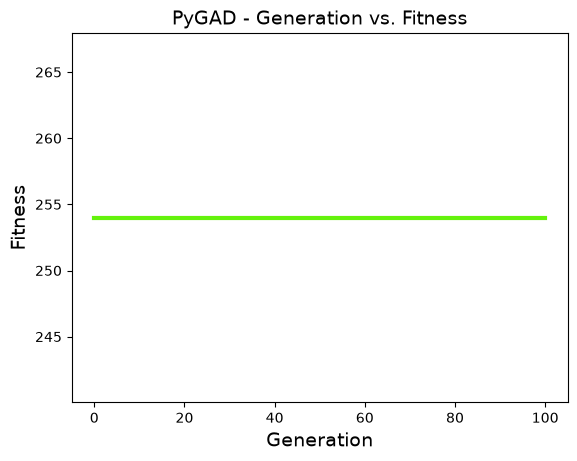

In [52]:
def main():
    ga_instance = pygad.GA(
        num_generations=NUM_EVOLUTIONS,
        num_parents_mating=POPULATION_SIZE // 2,
        fitness_func=fitness_func,
        sol_per_pop=POPULATION_SIZE,
        num_genes=N_OBJECTS,
        gene_space=[0, 1],  # Echivalentul lui BooleanGene (0 = Nu, 1 = Da)
        gene_type=int,
        parent_selection_type="sss",
        keep_elitism=1,
        crossover_type="single_point",
        crossover_probability=0.35,
        mutation_type="random",
        mutation_probability=1 / 10,
        on_generation=on_generation,
    )
    ga_instance.run()
    ga_instance.plot_fitness()
if __name__ == "__main__":
    main()

In [53]:
N_OBJECTS = 10
MAX_VOLUME = 30
MAX_ITEMS_PER_TYPE = 5
ALPHA = 100  # Factorul de penalizare pentru depasirea volumului
# vol_i = i, val_i = i^2 pentru i = 1..10
VOLUMES = [i for i in range(1, N_OBJECTS + 1)]       # [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
VALUES = [i ** 2 for i in range(1, N_OBJECTS + 1)]   # [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]
NUM_EVOLUTIONS = 400
POPULATION_SIZE = 100

In [54]:
def display_individual(gen, solution):
    v_tot = get_total_volume(solution)
    total_val = get_total_value(solution)
    fitness = fitness_func(None, solution, 0)
    genes_str = " ".join(str(int(g)) for g in solution)
    print(
        f"Gen {gen:3d} | "
        f"Cantitati: [{genes_str}] | "
        f"Volum: {v_tot:2d}/{MAX_VOLUME} | "
        f"Valoare: {total_val:3d} | "
        f"Fitness J: {fitness:.1f}"
    )

Gen   1 | Cantitati: [2 2 0 0 0 1 4 0 0 0] | Volum: 40/30 | Valoare: 242 | Fitness J: -9758.0
Gen   2 | Cantitati: [2 2 0 0 0 1 4 0 0 0] | Volum: 40/30 | Valoare: 242 | Fitness J: -9758.0
Gen   3 | Cantitati: [1 2 1 3 1 0 0 0 0 0] | Volum: 25/30 | Valoare:  91 | Fitness J: 91.0
Gen   4 | Cantitati: [2 0 0 0 0 0 4 0 0 0] | Volum: 30/30 | Valoare: 198 | Fitness J: 198.0
Gen   5 | Cantitati: [2 0 0 0 0 0 4 0 0 0] | Volum: 30/30 | Valoare: 198 | Fitness J: 198.0
Gen   6 | Cantitati: [3 0 0 2 0 0 0 0 1 1] | Volum: 30/30 | Valoare: 216 | Fitness J: 216.0
Gen   7 | Cantitati: [3 0 0 2 0 0 0 0 1 1] | Volum: 30/30 | Valoare: 216 | Fitness J: 216.0
Gen   8 | Cantitati: [3 0 0 2 0 0 0 0 1 1] | Volum: 30/30 | Valoare: 216 | Fitness J: 216.0
Gen   9 | Cantitati: [3 0 0 2 0 0 0 0 1 1] | Volum: 30/30 | Valoare: 216 | Fitness J: 216.0
Gen  10 | Cantitati: [1 1 0 0 0 1 0 0 1 1] | Volum: 28/30 | Valoare: 222 | Fitness J: 222.0
Gen  11 | Cantitati: [1 1 0 0 0 1 0 0 1 1] | Volum: 28/30 | Valoare: 222 | Fi

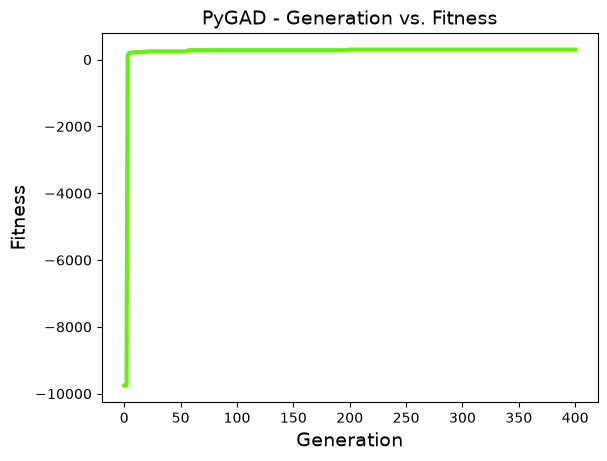

In [55]:
def main():
    ga_instance = pygad.GA(
        num_generations=NUM_EVOLUTIONS,
        num_parents_mating=POPULATION_SIZE // 2,
        fitness_func=fitness_func,
        sol_per_pop=POPULATION_SIZE,
        num_genes=N_OBJECTS,
        # Maxim 5 obiecte din fiecare tip -> valori intregi in {0, 1, 2, 3, 4, 5}
        gene_space=range(0, MAX_ITEMS_PER_TYPE + 1),
        gene_type=int,
        parent_selection_type="sss",
        keep_elitism=1,
        crossover_type="single_point",
        crossover_probability=0.5,
        mutation_type="random",
        mutation_probability=1 / 5,
        on_generation=on_generation,
    )
    ga_instance.run()
    ga_instance.plot_fitness()
if __name__ == "__main__":
    main()